<a href="https://colab.research.google.com/github/asetya/BigData/blob/master/Orb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==============================================================================
# ORB (Oriented FAST and Rotated BRIEF) Implemented from Scratch
# Google Colab Compatible
# ==============================================================================

import io
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# ------------------------------------------------------------------------------
# 1. Flexible Input Loader
# ------------------------------------------------------------------------------

def load_input_image(source):
    """Loads any image from a URL, Colab byte upload, or local path."""
    if isinstance(source, np.ndarray):
        img_bgr = source.copy()
        if len(img_bgr.shape) == 2:
            img_bgr = cv2.cvtColor(img_bgr, cv2.COLOR_GRAY2BGR)
    elif isinstance(source, bytes):
        nparr = np.frombuffer(source, np.uint8)
        img_bgr = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    elif isinstance(source, str) and (source.startswith('http://') or source.startswith('https://')):
        req = urllib.request.Request(source, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as resp:
            nparr = np.frombuffer(resp.read(), np.uint8)
            img_bgr = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    elif isinstance(source, str):
        img_bgr = cv2.imread(source, cv2.IMREAD_COLOR)
    else:
        raise ValueError("Unsupported image source.")

    if img_bgr is None:
        raise ValueError(f"Failed to load image from: {source}")

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    return img_rgb, img_gray


# ------------------------------------------------------------------------------
# 2. FAST-9 Keypoint Detector
# ------------------------------------------------------------------------------

# 16-pixel Bresenham circle coordinates relative to center (dy, dx)
BRESENHAM_CIRCLE = np.array([
    [-3,  0], [-3,  1], [-2,  2], [-1,  3],
    [ 0,  3], [ 1,  3], [ 2,  2], [ 3,  1],
    [ 3,  0], [ 3, -1], [ 2, -2], [ 1, -3],
    [ 0, -3], [-1, -3], [-2, -2], [-3, -1]
])

def fast9_detect(img_gray, threshold=25, border=16):
    """
    Detects keypoints using FAST-9 (9 contiguous pixels on the circle).
    """
    h, w = img_gray.shape
    img = img_gray.astype(np.int32)
    keypoints = []

    for y in range(border, h - border):
        for x in range(border, w - border):
            Ip = img[y, x]

            # Fast test: check cardinal points (indices 0, 4, 8, 12)
            cardinals = [img[y + BRESENHAM_CIRCLE[idx, 0], x + BRESENHAM_CIRCLE[idx, 1]] for idx in (0, 4, 8, 12)]
            brighter = sum(val > Ip + threshold for val in cardinals)
            darker   = sum(val < Ip - threshold for val in cardinals)
            if brighter < 3 and darker < 3:
                continue

            # Full 16-pixel circular ring evaluation
            circle_vals = img[y + BRESENHAM_CIRCLE[:, 0], x + BRESENHAM_CIRCLE[:, 1]]
            is_bright = (circle_vals > Ip + threshold).astype(int)
            is_dark   = (circle_vals < Ip - threshold).astype(int)

            # Check 9 contiguous matches around the circular ring
            is_bright_extended = np.tile(is_bright, 2)
            is_dark_extended   = np.tile(is_dark, 2)

            max_bright_run = max(map(len, "".join(map(str, is_bright_extended)).split("0")))
            max_dark_run   = max(map(len, "".join(map(str, is_dark_extended)).split("0")))

            if max_bright_run >= 9 or max_dark_run >= 9:
                keypoints.append((x, y))

    return keypoints


# ------------------------------------------------------------------------------
# 3. Harris Response Filtering & Ranking
# ------------------------------------------------------------------------------

def filter_by_harris(img_gray, keypoints, max_corners=500, k=0.04):
    """
    Evaluates the Harris corner response at each candidate coordinate
    to prune edge-like responses and select the top-N strongest points.
    """
    if not keypoints:
        return []

    img = img_gray.astype(np.float64)
    Ix = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    Iy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

    Sxx = gaussian_filter(Ix ** 2, sigma=1.0)
    Syy = gaussian_filter(Iy ** 2, sigma=1.0)
    Sxy = gaussian_filter(Ix * Iy, sigma=1.0)

    det_M = (Sxx * Syy) - (Sxy ** 2)
    trace_M = Sxx + Syy
    R = det_M - k * (trace_M ** 2)

    scored_kps = [(x, y, R[y, x]) for (x, y) in keypoints if R[y, x] > 0]
    scored_kps.sort(key=lambda item: item[2], reverse=True)

    return [(item[0], item[1]) for item in scored_kps[:max_corners]]


# ------------------------------------------------------------------------------
# 4. Intensity Centroid Orientation (oFAST)
# ------------------------------------------------------------------------------

def compute_orientation(img_gray, keypoints, patch_radius=15):
    """
    Computes canonical patch orientation via image moments:
    m_pq = sum(x^p * y^q * I(x, y))
    theta = atan2(m_01, m_10)
    """
    oriented_kps = []
    h, w = img_gray.shape
    img = img_gray.astype(np.float64)

    # Circular mask grid
    y_grid, x_grid = np.ogrid[-patch_radius:patch_radius + 1, -patch_radius:patch_radius + 1]
    circular_mask = (x_grid ** 2 + y_grid ** 2) <= (patch_radius ** 2)

    for x, y in keypoints:
        if (x - patch_radius < 0 or x + patch_radius >= w or
            y - patch_radius < 0 or y + patch_radius >= h):
            continue

        patch = img[y - patch_radius : y + patch_radius + 1,
                    x - patch_radius : x + patch_radius + 1]
        masked_patch = patch * circular_mask

        # Moments
        m10 = np.sum(x_grid * masked_patch)
        m01 = np.sum(y_grid * masked_patch)

        theta = np.arctan2(m01, m10)
        oriented_kps.append((x, y, theta))

    return oriented_kps


# ------------------------------------------------------------------------------
# 5. Steered BRIEF Descriptors (rBRIEF)
# ------------------------------------------------------------------------------

def generate_brief_pattern(num_pairs=256, patch_size=31, seed=42):
    """Generates standard Gaussian pair sampling offsets."""
    rng = np.random.default_rng(seed)
    sigma = patch_size / 5.0
    # Samples 256 pairs of (ptA, ptB) -> shape (256, 2), (256, 2)
    p_x = rng.normal(0, sigma, (num_pairs, 2))
    p_y = rng.normal(0, sigma, (num_pairs, 2))
    p_x = np.clip(np.round(p_x), -patch_size // 2, patch_size // 2).astype(np.int32)
    p_y = np.clip(np.round(p_y), -patch_size // 2, patch_size // 2).astype(np.int32)
    return p_x, p_y

def compute_orb_descriptors(img_gray, oriented_kps, p_x, p_y):
    """
    Computes 256-bit binary descriptors steered along patch orientation theta:
    S_theta = R(theta) * S
    """
    # Smooth before sampling to suppress pixel sensor noise
    smoothed = cv2.GaussianBlur(img_gray, (7, 7), 2.0).astype(np.float32)
    h, w = smoothed.shape

    valid_kps = []
    descriptors = []

    for x, y, theta in oriented_kps:
        cos_t = np.cos(theta)
        sin_t = np.sin(theta)
        rot = np.array([[cos_t, -sin_t],
                        [sin_t,  cos_t]])

        # Steer pair sampling locations
        p_x_rot = np.round(p_x @ rot.T).astype(np.int32)
        p_y_rot = np.round(p_y @ rot.T).astype(np.int32)

        # Sampling coordinates in image space
        x1 = x + p_x_rot[:, 0]
        y1 = y + p_x_rot[:, 1]
        x2 = x + p_y_rot[:, 0]
        y2 = y + p_y_rot[:, 1]

        # Boundary check
        if (np.any(x1 < 0) or np.any(x1 >= w) or np.any(y1 < 0) or np.any(y1 >= h) or
            np.any(x2 < 0) or np.any(x2 >= w) or np.any(y2 < 0) or np.any(y2 >= h)):
            continue

        # 256 boolean pairwise tests: tau(p; x, y) = 1 if I(x) < I(y) else 0
        bits = (smoothed[y1, x1] < smoothed[y2, x2]).astype(np.uint8)

        # Pack 256 bits into a 32-byte array (np.uint8)
        desc_bytes = np.packbits(bits)

        valid_kps.append((x, y, theta))
        descriptors.append(desc_bytes)

    return valid_kps, np.array(descriptors, dtype=np.uint8)


# ------------------------------------------------------------------------------
# 6. Complete ORB Multi-Scale Pipeline
# ------------------------------------------------------------------------------

def custom_orb_detector(image_source, n_features=300, n_levels=3, scale_factor=1.2):
    """
    Executes the complete ORB detection and description across an image pyramid.
    """
    img_rgb, img_gray = load_input_image(image_source)
    p_x, p_y = generate_brief_pattern(num_pairs=256, patch_size=31)

    all_kps = []
    all_descs = []
    curr_img = img_gray.copy()
    current_scale = 1.0

    features_per_level = int(n_features / n_levels)

    for level in range(n_levels):
        # 1. FAST-9
        raw_kps = fast9_detect(curr_img, threshold=20, border=16)

        # 2. Harris Ranking
        harris_kps = filter_by_harris(curr_img, raw_kps, max_corners=features_per_level)

        # 3. Orientation via Moments
        oriented_kps = compute_orientation(curr_img, harris_kps, patch_radius=15)

        # 4. Steered BRIEF
        kps_level, descs_level = compute_orb_descriptors(curr_img, oriented_kps, p_x, p_y)

        # Project coordinates back to base image resolution
        for (x, y, theta) in kps_level:
            orig_x = int(round(x * current_scale))
            orig_y = int(round(y * current_scale))
            all_kps.append((orig_x, orig_y, theta, current_scale))

        if len(descs_level) > 0:
            all_descs.append(descs_level)

        # Downsample for next pyramid level
        current_scale *= scale_factor
        new_w = int(img_gray.shape[1] / current_scale)
        new_h = int(img_gray.shape[0] / current_scale)
        curr_img = cv2.resize(img_gray, (new_w, new_h), interpolation=cv2.INTER_AREA)

    descriptors_matrix = np.vstack(all_descs) if all_descs else np.empty((0, 32), dtype=np.uint8)

    # --------------------------------------------------------------------------
    # Visualization: Keypoints with Oriented Vectors
    # --------------------------------------------------------------------------
    overlay = img_rgb.copy()
    for (x, y, theta, scale) in all_kps:
        r = int(5 * scale)
        cv2.circle(overlay, (x, y), r, (0, 255, 60), 1)
        # Draw orientation vector
        end_x = int(x + r * 2 * np.cos(theta))
        end_y = int(y + r * 2 * np.sin(theta))
        cv2.line(overlay, (x, y), (end_x, end_y), (255, 30, 0), 2)

    fig, ax = plt.subplots(figsize=(10, 8), dpi=120)
    ax.imshow(overlay)
    ax.set_title(f"Custom ORB: Detected {len(all_kps)} Keypoints with Orientations", fontsize=12)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

    return all_kps, descriptors_matrix

Saving face.jpg to face.jpg
Executing ORB on: face.jpg


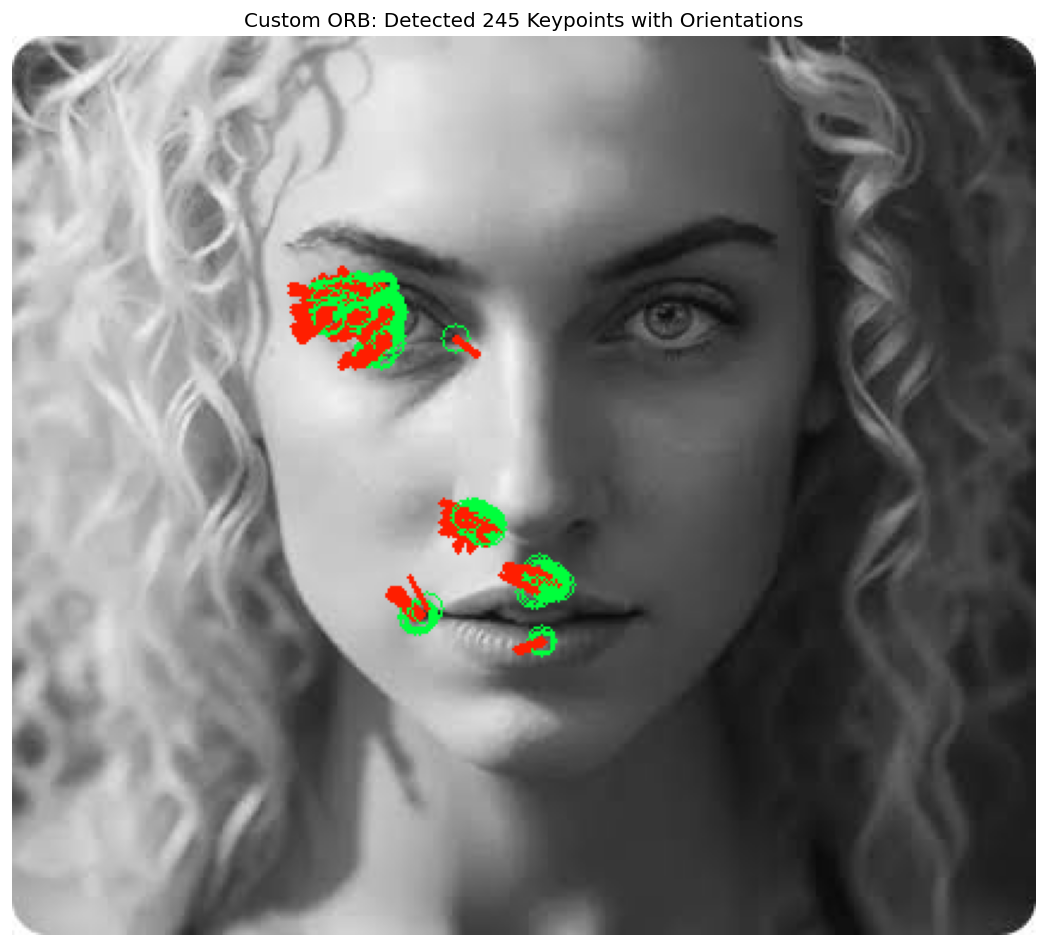

In [2]:
from google.colab import files

uploaded = files.upload()
for name, data in uploaded.items():
    print(f"Executing ORB on: {name}")
    kps, descs = custom_orb_detector(data, n_features=250, n_levels=3)